In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head())

Saving cleand_sales_new_data.csv to cleand_sales_new_data.csv
Dataset loaded successfully!
Rows: 9,800
Columns: 21


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Year,Month,Month Name,Day
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2017,11,November,8
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,2017,11,November,8
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2017,6,June,12
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,2016,10,October,11
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2016,10,October,11


In [7]:
print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nMISSING VALUES")
print("=" * 50)

missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
    .sort_values(ascending=False)
    .to_frame("Missing Values")
)

print("\nDUPLICATE ROWS")
print("=" * 50)

print("Duplicate rows:", df.duplicated().sum())

print("\nNUMERICAL SUMMARY")
print("=" * 50)

display(df.describe().T)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9800 non-null   int64  
 1   Order ID       9800 non-null   object 
 2   Order Date     9800 non-null   object 
 3   Ship Date      9800 non-null   object 
 4   Ship Mode      9800 non-null   object 
 5   Customer ID    9800 non-null   object 
 6   Customer Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Region         9800 non-null   object 
 12  Product ID     9800 non-null   object 
 13  Category       9800 non-null   object 
 14  Sub-Category   9800 non-null   object 
 15  Product Name   9800 non-null   object 
 16  Sales          9800 non-null   float64
 17  Year           9800 non-null   i

,Missing Values



DUPLICATE ROWS
Duplicate rows: 0

NUMERICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
Row ID,9800.0,4900.500000,2829.160653,1.000,2450.750,4900.50,7350.250,9800.00
Sales,9800.0,230.769059,626.651875,0.444,17.248,54.49,210.605,22638.48
Year,9800.0,2016.724184,1.123984,2015.000,2016.000,2017.00,2018.000,2018.00
Month,9800.0,7.818469,3.281905,1.000,5.000,9.00,11.000,12.00
Day,9800.0,15.486837,8.753733,1.000,8.000,16.00,23.000,31.00


In [8]:
# ============================================
# DATA VALIDATION AND PREPARATION
# ============================================

# Work on a copy of the original dataset
df = df.copy()

# Convert date columns to datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    errors="coerce"
)

# Check invalid dates
print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())

# Check sales values
print("\nSales Validation")
print("Missing Sales:", df["Sales"].isna().sum())
print("Zero or Negative Sales:", (df["Sales"] <= 0).sum())

# Check date consistency
invalid_shipping_dates = (
    df["Ship Date"] < df["Order Date"]
).sum()

print("\nShipping Date Validation")
print("Ship Date Before Order Date:", invalid_shipping_dates)

# Validate year and month against Order Date
year_mismatch = (
    df["Year"] != df["Order Date"].dt.year
).sum()

month_mismatch = (
    df["Month"] != df["Order Date"].dt.month
).sum()

print("\nDate Component Validation")
print("Year Mismatches:", year_mismatch)
print("Month Mismatches:", month_mismatch)

# Display date range
print("\nOrder Date Range")
print("Start:", df["Order Date"].min())
print("End:", df["Order Date"].max())

# Preview the prepared data
display(
    df[
        [
            "Order ID",
            "Order Date",
            "Ship Date",
            "Sales",
            "Year",
            "Month"
        ]
    ].head()
)

Invalid Order Dates: 0
Invalid Ship Dates: 0

Sales Validation
Missing Sales: 0
Zero or Negative Sales: 0

Shipping Date Validation
Ship Date Before Order Date: 0

Date Component Validation
Year Mismatches: 0
Month Mismatches: 0

Order Date Range
Start: 2015-01-03 00:00:00
End: 2018-12-30 00:00:00


,Order ID,Order Date,Ship Date,Sales,Year,Month
0,CA-2017-152156,2017-11-08,2017-11-11,261.9600,2017,11
1,CA-2017-152156,2017-11-08,2017-11-11,731.9400,2017,11
2,CA-2017-138688,2017-06-12,2017-06-16,14.6200,2017,6
3,US-2016-108966,2016-10-11,2016-10-18,957.5775,2016,10
4,US-2016-108966,2016-10-11,2016-10-18,22.3680,2016,10


In [9]:
# ============================================
# SALES PERFORMANCE ANALYSIS
# ============================================

total_sales = df["Sales"].sum()

total_orders = df["Order ID"].nunique()

total_customers = df["Customer ID"].nunique()

total_products = df["Product ID"].nunique()

average_sales_per_record = df["Sales"].mean()

average_order_value = (
    df.groupby("Order ID")["Sales"].sum().mean()
)

print("=" * 45)
print("SALES PERFORMANCE SUMMARY")
print("=" * 45)

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Unique Customers: {total_customers:,}")
print(f"Unique Products: {total_products:,}")
print(
    f"Average Sales per Record: "
    f"${average_sales_per_record:,.2f}"
)
print(f"Average Order Value: ${average_order_value:,.2f}")

SALES PERFORMANCE SUMMARY
Total Sales: $2,261,536.78
Total Orders: 4,922
Unique Customers: 793
Unique Products: 1,861
Average Sales per Record: $230.77
Average Order Value: $459.48


In [10]:
# ============================================
# YEARLY SALES ANALYSIS
# ============================================

yearly_sales = (
    df.groupby("Year")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Orders=("Order ID", "nunique"),
          Total_Customers=("Customer ID", "nunique")
      )
      .sort_index()
)

yearly_sales["Sales_Growth_%"] = (
    yearly_sales["Total_Sales"]
    .pct_change()
    .mul(100)
)

display(yearly_sales.round(2))

,Total_Sales,Total_Orders,Total_Customers,Sales_Growth_%
Year,,,,
2015,479856.21,947,589,NaN
2016,459436.01,1019,567,-4.26
2017,600192.55,1295,635,30.64
2018,722052.02,1661,690,20.30


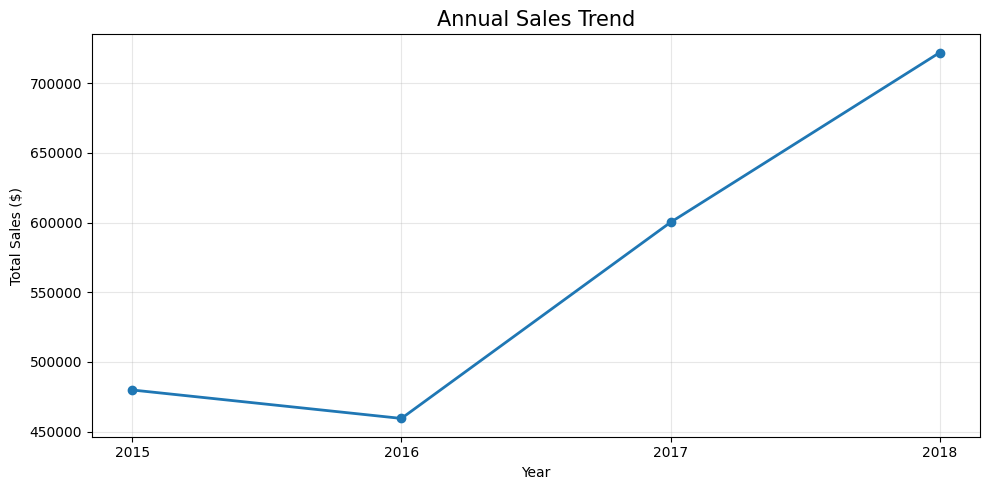

In [11]:
# ============================================
# YEARLY SALES VISUALIZATION
# ============================================

plt.figure(figsize=(10, 5))

plt.plot(
    yearly_sales.index,
    yearly_sales["Total_Sales"],
    marker="o",
    linewidth=2
)

plt.title("Annual Sales Trend", fontsize=15)
plt.xlabel("Year")
plt.ylabel("Total Sales ($)")
plt.xticks(yearly_sales.index)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
# ============================================
# MONTHLY SALES ANALYSIS
# ============================================

# Ensure Order Date is in datetime format
df["Order Date"] = pd.to_datetime(df["Order Date"])

# Aggregate sales by month across all years
monthly_sales = (
    df.groupby("Month")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reindex(range(1, 13))
)

# Add month names
monthly_sales["Month_Name"] = (
    pd.to_datetime(monthly_sales.index, format="%m")
      .strftime("%B")
)

display(monthly_sales.round(2))

,Total_Sales,Total_Orders,Month_Name
Month,,,
1,94291.63,174,January
2,59371.12,161,February
3,197573.59,346,March
4,136283.00,337,April
5,154086.72,363,May
6,145837.52,354,June
7,145535.69,331,July
8,157315.93,335,August
9,300103.41,674,September


In [13]:
# ============================================
# MONTHLY SALES BY YEAR
# ============================================

df["Order Date"] = pd.to_datetime(df["Order Date"])

monthly_yearly_sales = (
    df.groupby(["Year", "Month"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Orders=("Order ID", "nunique")
      )
      .reset_index()
)

# Create a table with years as rows and months as columns
sales_pivot = monthly_yearly_sales.pivot(
    index="Year",
    columns="Month",
    values="Total_Sales"
)

# Replace month numbers with names
sales_pivot.columns = [
    pd.to_datetime(month, format="%m").strftime("%b")
    for month in sales_pivot.columns
]

display(sales_pivot.round(2))

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Year,,,,,,,,,,,,
2015,14205.71,4519.89,55205.80,27906.86,23644.30,34322.94,33781.54,27117.54,81623.53,31453.39,77907.66,68167.06
2016,18066.96,11951.41,32339.32,34154.47,29959.53,23599.37,28608.26,36818.34,63133.61,31011.74,75249.40,74543.60
2017,18542.49,22978.82,51165.06,38679.77,56656.91,39724.49,38320.78,30542.20,69193.39,59583.03,79066.50,95739.12
2018,43476.47,19921.00,58863.41,35541.91,43825.98,48190.73,44825.10,62837.85,86152.89,77448.13,117938.16,83030.39


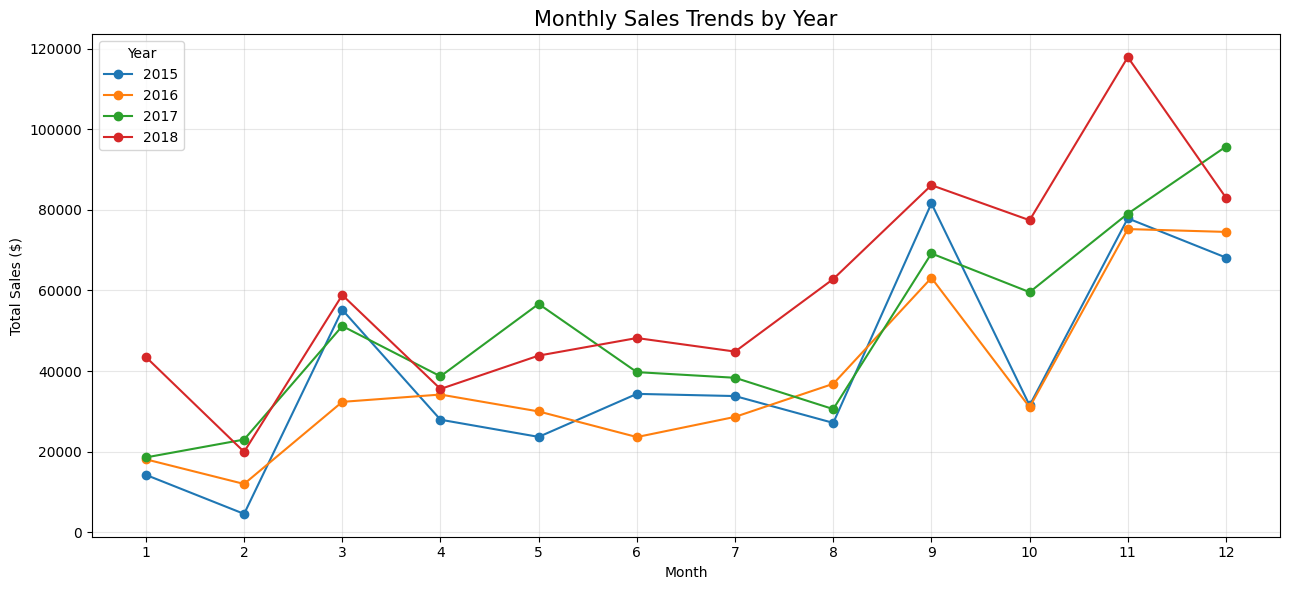

In [14]:
# ============================================
# MONTHLY SALES TREND BY YEAR
# ============================================

plt.figure(figsize=(13, 6))

for year in sorted(df["Year"].unique()):
    yearly_data = monthly_yearly_sales[
        monthly_yearly_sales["Year"] == year
    ].sort_values("Month")

    plt.plot(
        yearly_data["Month"],
        yearly_data["Total_Sales"],
        marker="o",
        label=str(year)
    )

plt.title("Monthly Sales Trends by Year", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Total Sales ($)")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
# ============================================
# SALES BY PRODUCT CATEGORY
# ============================================

category_sales = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Orders=("Order ID", "nunique"),
          Unique_Products=("Product ID", "nunique")
      )
      .sort_values("Total_Sales", ascending=False)
)

category_sales["Sales_Share_%"] = (
    category_sales["Total_Sales"]
    / df["Sales"].sum()
    * 100
)

display(category_sales.round(2))

,Total_Sales,Total_Orders,Unique_Products,Sales_Share_%
Category,,,,
Technology,827455.87,1519,404,36.59
Furniture,728658.58,1727,375,32.22
Office Supplies,705422.33,3676,1082,31.19


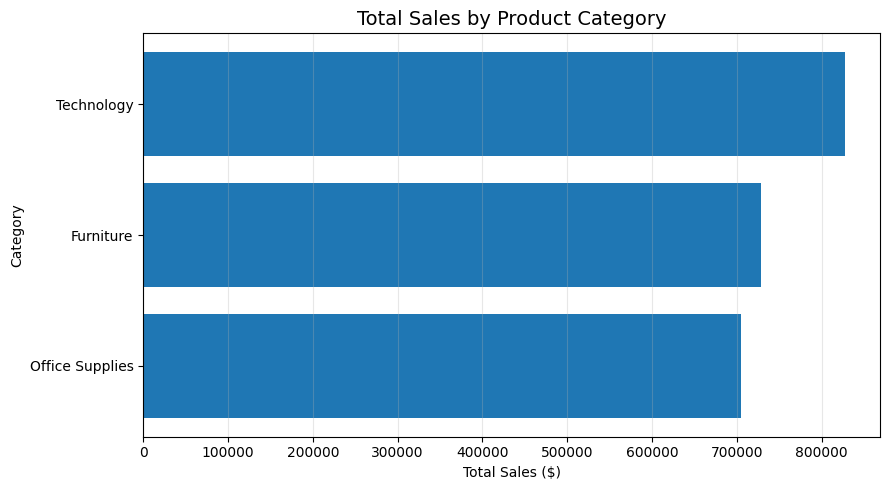

In [16]:
# ============================================
# CATEGORY SALES VISUALIZATION
# ============================================

category_sales_sorted = category_sales.sort_values(
    "Total_Sales",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    category_sales_sorted.index,
    category_sales_sorted["Total_Sales"]
)

plt.title("Total Sales by Product Category", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [17]:
# ============================================
# SALES BY SUB-CATEGORY
# ============================================

subcategory_sales = (
    df.groupby(["Category", "Sub-Category"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Orders=("Order ID", "nunique"),
          Unique_Products=("Product ID", "nunique")
      )
      .reset_index()
      .sort_values("Total_Sales", ascending=False)
)

subcategory_sales["Sales_Share_%"] = (
    subcategory_sales["Total_Sales"]
    / df["Sales"].sum()
    * 100
)

display(subcategory_sales.round(2))

,Category,Sub-Category,Total_Sales,Total_Orders,Unique_Products,Sales_Share_%
16,Technology,Phones,327782.45,803,184,14.49
1,Furniture,Chairs,322822.73,566,87,14.27
11,Office Supplies,Storage,219343.39,764,130,9.70
3,Furniture,Tables,202810.63,302,57,8.97
6,Office Supplies,Binders,200028.78,1291,210,8.84
15,Technology,Machines,189238.63,112,63,8.37
13,Technology,Accessories,164186.70,702,144,7.26
14,Technology,Copiers,146248.09,66,13,6.47
0,Furniture,Bookcases,113813.20,222,49,5.03
4,Office Supplies,Appliances,104618.40,444,98,4.63


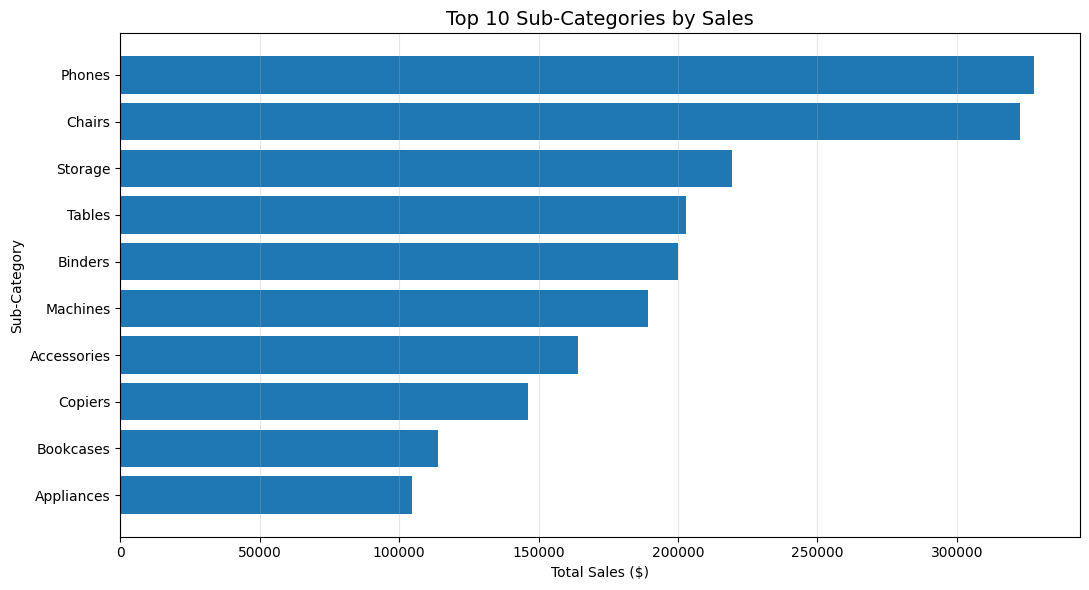

In [18]:
# ============================================
# TOP 10 SUB-CATEGORIES BY SALES
# ============================================

top_10_subcategories = subcategory_sales.head(10).sort_values(
    "Total_Sales",
    ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    top_10_subcategories["Sub-Category"],
    top_10_subcategories["Total_Sales"]
)

plt.title("Top 10 Sub-Categories by Sales", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("Sub-Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Display Top 10 Sub-Categories by Sales

display(
    subcategory_sales
    .head(10)
    .reset_index(drop=True)
    .round(2)
)

,Category,Sub-Category,Total_Sales,Total_Orders,Unique_Products,Sales_Share_%
0,Technology,Phones,327782.45,803,184,14.49
1,Furniture,Chairs,322822.73,566,87,14.27
2,Office Supplies,Storage,219343.39,764,130,9.70
3,Furniture,Tables,202810.63,302,57,8.97
4,Office Supplies,Binders,200028.78,1291,210,8.84
5,Technology,Machines,189238.63,112,63,8.37
6,Technology,Accessories,164186.70,702,144,7.26
7,Technology,Copiers,146248.09,66,13,6.47
8,Furniture,Bookcases,113813.20,222,49,5.03
9,Office Supplies,Appliances,104618.40,444,98,4.63


In [20]:
# Sales Performance by Region

region_sales = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

region_sales["Sales_Share_%"] = (
    region_sales["Total_Sales"] / df["Sales"].sum() * 100
)

display(region_sales.round(2))

,Region,Total_Sales,Total_Orders,Unique_Customers,Sales_Share_%
3,West,710219.68,1587,681,31.40
1,East,669518.73,1369,669,29.60
0,Central,492646.91,1156,626,21.78
2,South,389151.46,810,509,17.21


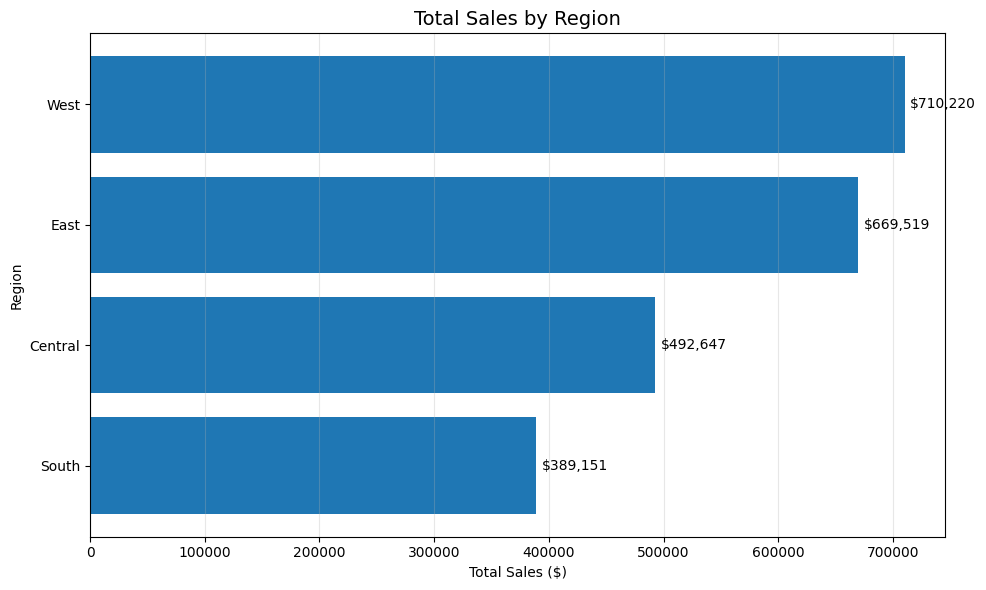

In [21]:
# Sales by Region - Bar Chart

region_sales_sorted = region_sales.sort_values(
    "Total_Sales", ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    region_sales_sorted["Region"],
    region_sales_sorted["Total_Sales"]
)

plt.title("Total Sales by Region", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("Region")

plt.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in region_sales_sorted["Total_Sales"]
    ],
    padding=4
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
# Regional Sales Analysis - Results

region_sales_sorted = region_sales.sort_values(
    "Total_Sales", ascending=False
).reset_index(drop=True)

display(region_sales_sorted.round(2))

# Identify the highest and lowest sales regions
highest_region = region_sales_sorted.iloc[0]
lowest_region = region_sales_sorted.iloc[-1]

# Calculate the sales gap
sales_gap = (
    highest_region["Total_Sales"]
    - lowest_region["Total_Sales"]
)

sales_gap_percentage = (
    sales_gap / highest_region["Total_Sales"] * 100
)

print("\nKEY FINDINGS")
print("-" * 50)

print(
    f"Highest Sales Region: {highest_region['Region']} "
    f"(${highest_region['Total_Sales']:,.2f})"
)

print(
    f"Sales Share: {highest_region['Sales_Share_%']:.2f}%"
)

print(
    f"Lowest Sales Region: {lowest_region['Region']} "
    f"(${lowest_region['Total_Sales']:,.2f})"
)

print(
    f"Sales Share: {lowest_region['Sales_Share_%']:.2f}%"
)

print(f"Sales Gap: ${sales_gap:,.2f}")

print(
    f"Gap as a Percentage of Highest Region Sales: "
    f"{sales_gap_percentage:.2f}%"
)

,Region,Total_Sales,Total_Orders,Unique_Customers,Sales_Share_%
0,West,710219.68,1587,681,31.40
1,East,669518.73,1369,669,29.60
2,Central,492646.91,1156,626,21.78
3,South,389151.46,810,509,17.21



KEY FINDINGS
--------------------------------------------------
Highest Sales Region: West ($710,219.68)
Sales Share: 31.40%
Lowest Sales Region: South ($389,151.46)
Sales Share: 17.21%
Sales Gap: $321,068.23
Gap as a Percentage of Highest Region Sales: 45.21%


In [23]:
# Sales Performance by State

state_sales = (
    df.groupby("State")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

state_sales["Sales_Share_%"] = (
    state_sales["Total_Sales"] / df["Sales"].sum() * 100
)

top_10_states = state_sales.head(10).reset_index(drop=True)

display(top_10_states.round(2))

,State,Total_Sales,Total_Orders,Unique_Customers,Sales_Share_%
0,California,446306.46,1002,570,19.73
1,New York,306361.15,547,409,13.55
2,Texas,168572.53,480,367,7.45
3,Washington,135206.85,254,223,5.98
4,Pennsylvania,116276.65,285,255,5.14
5,Florida,88436.53,197,178,3.91
6,Illinois,79236.52,270,231,3.50
7,Michigan,76136.07,116,105,3.37
8,Ohio,75130.35,227,196,3.32
9,Virginia,70636.72,115,107,3.12


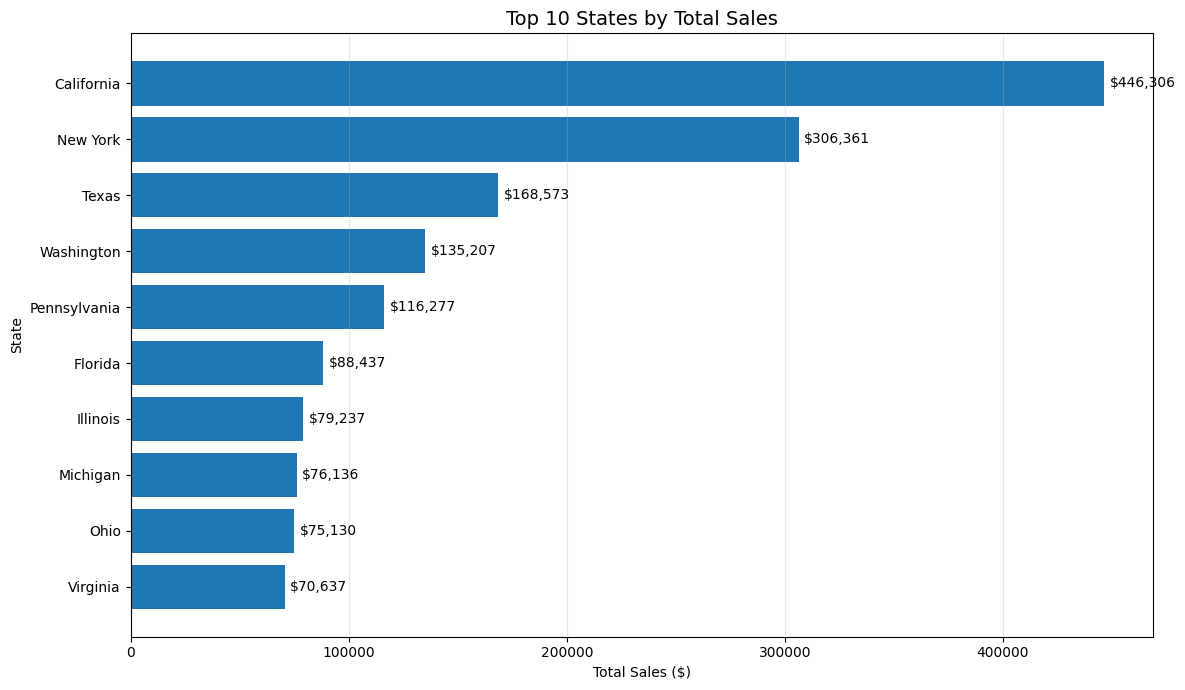

In [24]:
# Top 10 States by Sales

states_chart = top_10_states.sort_values(
    "Total_Sales", ascending=True
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    states_chart["State"],
    states_chart["Total_Sales"]
)

plt.title("Top 10 States by Total Sales", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("State")

plt.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in states_chart["Total_Sales"]
    ],
    padding=4
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [25]:
# Sales Performance by City

city_sales = (
    df.groupby(["State", "City"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Unique_Customers=("Customer ID", "nunique")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

city_sales["Sales_Share_%"] = (
    city_sales["Total_Sales"] / df["Sales"].sum() * 100
)

top_10_cities = city_sales.head(10).reset_index(drop=True)

display(top_10_cities.round(2))

,State,City,Total_Sales,Total_Orders,Unique_Customers,Sales_Share_%
0,New York,New York City,252462.55,439,349,11.16
1,California,Los Angeles,173420.18,378,300,7.67
2,Washington,Seattle,116106.32,210,187,5.13
3,California,San Francisco,109041.12,261,230,4.82
4,Pennsylvania,Philadelphia,108841.75,262,237,4.81
5,Texas,Houston,63956.14,186,170,2.83
6,Illinois,Chicago,47820.13,166,150,2.11
7,California,San Diego,47521.03,88,86,2.10
8,Michigan,Detroit,42446.94,53,50,1.88
9,Florida,Jacksonville,39133.33,38,38,1.73


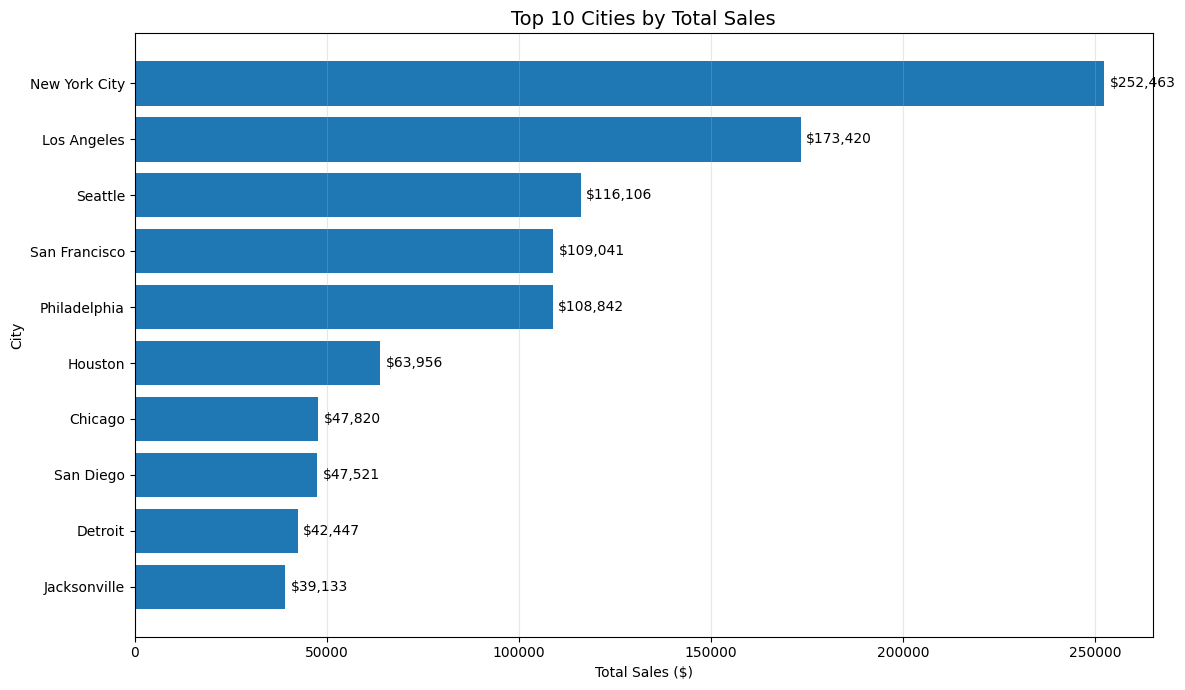

In [26]:
# Top 10 Cities by Sales

cities_chart = top_10_cities.sort_values(
    "Total_Sales", ascending=True
)

plt.figure(figsize=(12, 7))

bars = plt.barh(
    cities_chart["City"],
    cities_chart["Total_Sales"]
)

plt.title("Top 10 Cities by Total Sales", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("City")

plt.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in cities_chart["Total_Sales"]
    ],
    padding=4
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
# Customer Purchasing Behavior Analysis

customer_analysis = (
    df.groupby(["Customer ID", "Customer Name"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Total_Records=("Order ID", "size")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

customer_analysis["Sales_Share_%"] = (
    customer_analysis["Total_Sales"]
    / df["Sales"].sum()
    * 100
)

# Display the top 10 customers by sales
top_10_customers = (
    customer_analysis.head(10)
    .reset_index(drop=True)
)

display(top_10_customers.round(2))

,Customer ID,Customer Name,Total_Sales,Total_Orders,Total_Records,Sales_Share_%
0,SM-20320,Sean Miller,25043.05,5,15,1.11
1,TC-20980,Tamara Chand,19052.22,5,12,0.84
2,RB-19360,Raymond Buch,15117.34,6,18,0.67
3,TA-21385,Tom Ashbrook,14595.62,4,10,0.65
4,AB-10105,Adrian Barton,14473.57,10,20,0.64
5,KL-16645,Ken Lonsdale,14175.23,12,29,0.63
6,SC-20095,Sanjit Chand,14142.33,9,22,0.63
7,HL-15040,Hunter Lopez,12873.30,6,11,0.57
8,SE-20110,Sanjit Engle,12209.44,11,19,0.54
9,CC-12370,Christopher Conant,12129.07,5,11,0.54


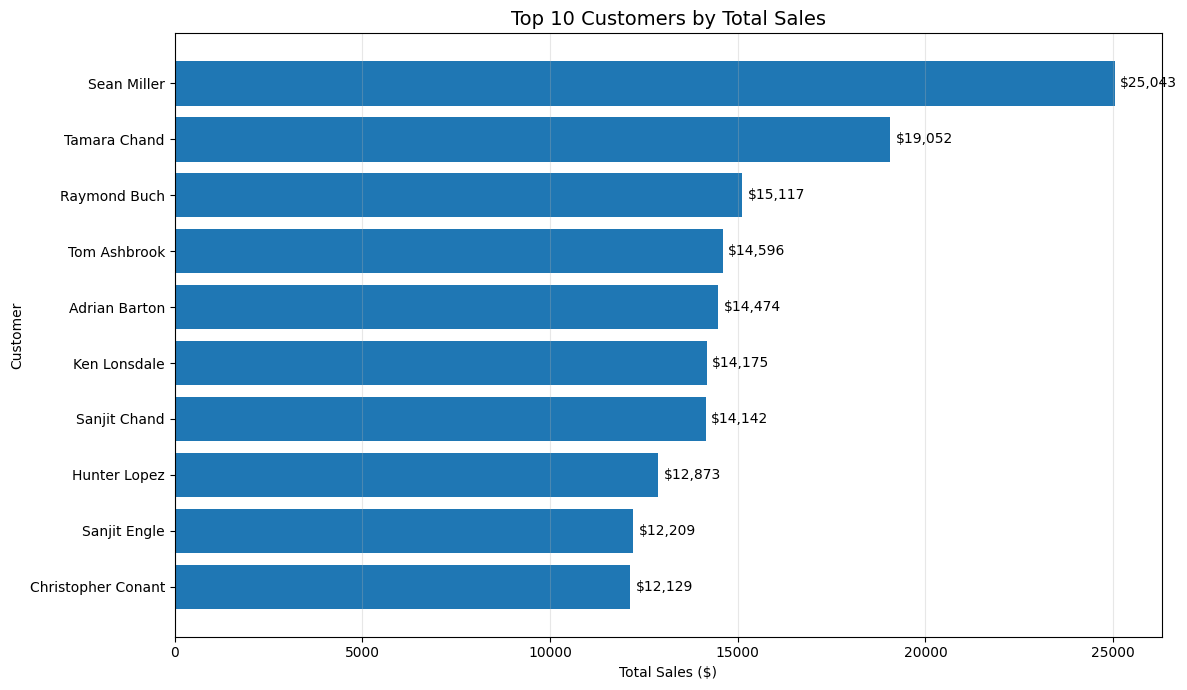

In [28]:
# Top 10 Customers by Sales

customers_chart = top_10_customers.sort_values(
    "Total_Sales", ascending=True
).copy()

plt.figure(figsize=(12, 7))

bars = plt.barh(
    customers_chart["Customer Name"],
    customers_chart["Total_Sales"]
)

plt.title("Top 10 Customers by Total Sales", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("Customer")

plt.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in customers_chart["Total_Sales"]
    ],
    padding=4
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [29]:
# Order Value Analysis

order_analysis = (
    df.groupby("Order ID")
    .agg(
        Order_Value=("Sales", "sum"),
        Order_Date=("Order Date", "first"),
        Customer_ID=("Customer ID", "first"),
        Customer_Name=("Customer Name", "first")
    )
    .reset_index()
)

print("Total Orders:", f"{len(order_analysis):,}")
print(
    "Average Order Value:",
    f"${order_analysis['Order_Value'].mean():,.2f}"
)
print(
    "Median Order Value:",
    f"${order_analysis['Order_Value'].median():,.2f}"
)
print(
    "Minimum Order Value:",
    f"${order_analysis['Order_Value'].min():,.2f}"
)
print(
    "Maximum Order Value:",
    f"${order_analysis['Order_Value'].max():,.2f}"
)

display(
    order_analysis
    .sort_values("Order_Value", ascending=False)
    .head(10)
    .round(2)
)

Total Orders: 4,922
Average Order Value: $459.48
Median Order Value: $151.88
Minimum Order Value: $0.56
Maximum Order Value: $23,661.23


,Order ID,Order_Value,Order_Date,Customer_ID,Customer_Name
533,CA-2015-145317,23661.23,2015-03-18,SM-20320,Sean Miller
1956,CA-2017-118689,18336.74,2017-10-02,TC-20980,Tamara Chand
3538,CA-2018-140151,14052.48,2018-03-23,RB-19360,Raymond Buch
3296,CA-2018-127180,13716.46,2018-10-22,TA-21385,Tom Ashbrook
473,CA-2015-139892,10539.90,2015-09-08,BM-11140,Becky Martin
4057,CA-2018-166709,10499.97,2018-11-17,HL-15040,Hunter Lopez
208,CA-2015-116904,9900.19,2015-09-23,SC-20095,Sanjit Chand
1932,CA-2017-117121,9892.74,2017-12-17,AB-10105,Adrian Barton
4444,US-2017-107440,9135.19,2017-04-16,BS-11365,Bill Shonely
2570,CA-2017-158841,8805.04,2017-02-02,SE-20110,Sanjit Engle


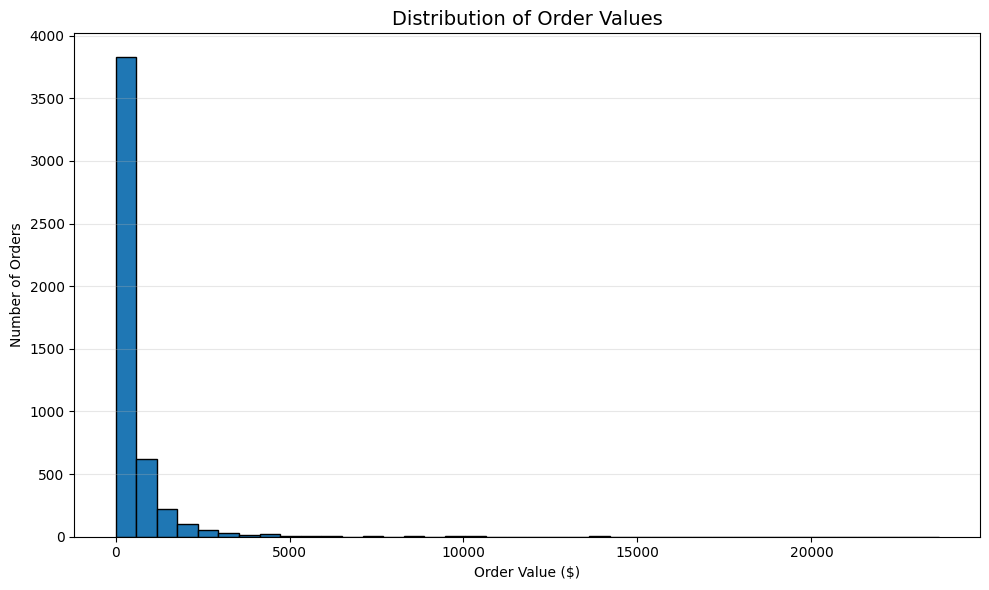

In [30]:
# Distribution of Order Values

plt.figure(figsize=(10, 6))

plt.hist(
    order_analysis["Order_Value"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Order Values", fontsize=14)
plt.xlabel("Order Value ($)")
plt.ylabel("Number of Orders")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [31]:
# Sales and Orders by Shipping Mode

shipping_analysis = (
    df.groupby("Ship Mode")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Orders=("Order ID", "nunique"),
        Average_Sales_Per_Record=("Sales", "mean")
    )
    .reset_index()
    .sort_values("Total_Sales", ascending=False)
)

shipping_analysis["Sales_Share_%"] = (
    shipping_analysis["Total_Sales"]
    / df["Sales"].sum()
    * 100
)

display(shipping_analysis.round(2))

,Ship Mode,Total_Sales,Total_Orders,Average_Sales_Per_Record,Sales_Share_%
3,Standard Class,1340831.31,2945,228.85,59.29
2,Second Class,449914.18,944,236.55,19.89
0,First Class,345572.26,772,230.23,15.28
1,Same Day,125219.04,261,232.75,5.54


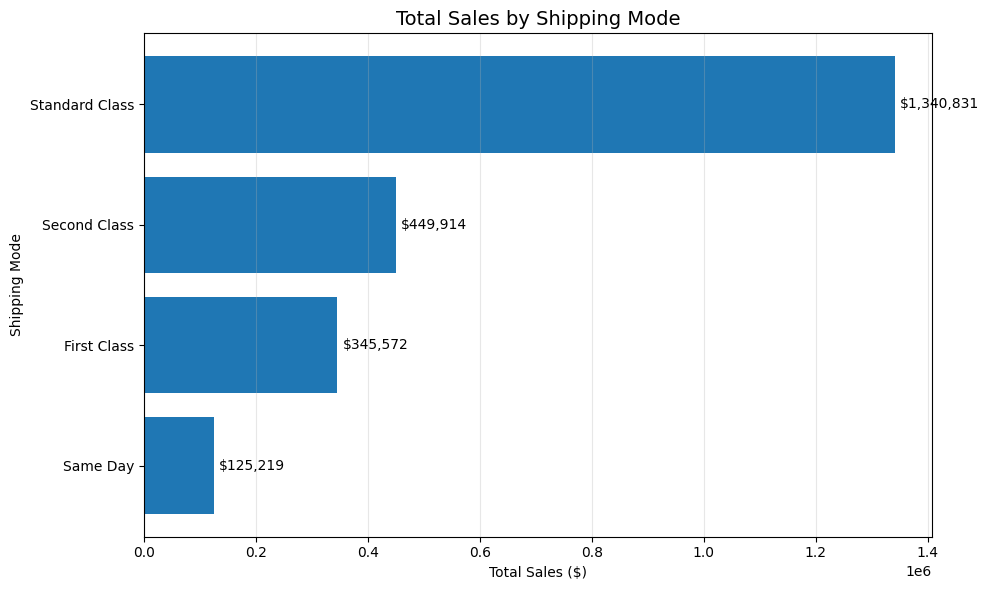

In [32]:
# Total Sales by Shipping Mode

shipping_chart = shipping_analysis.sort_values(
    "Total_Sales", ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    shipping_chart["Ship Mode"],
    shipping_chart["Total_Sales"]
)

plt.title("Total Sales by Shipping Mode", fontsize=14)
plt.xlabel("Total Sales ($)")
plt.ylabel("Shipping Mode")

plt.bar_label(
    bars,
    labels=[
        f"${value:,.0f}"
        for value in shipping_chart["Total_Sales"]
    ],
    padding=4
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
# Shipping Duration Analysis

shipping_data = df.copy()

shipping_data["Order Date"] = pd.to_datetime(
    shipping_data["Order Date"]
)

shipping_data["Ship Date"] = pd.to_datetime(
    shipping_data["Ship Date"]
)

# Calculate shipping duration in days
shipping_data["Shipping_Days"] = (
    shipping_data["Ship Date"]
    - shipping_data["Order Date"]
).dt.days

# Summarize shipping duration by shipping mode
shipping_duration = (
    shipping_data.groupby("Ship Mode")
    .agg(
        Average_Shipping_Days=("Shipping_Days", "mean"),
        Median_Shipping_Days=("Shipping_Days", "median"),
        Min_Shipping_Days=("Shipping_Days", "min"),
        Max_Shipping_Days=("Shipping_Days", "max"),
        Total_Records=("Shipping_Days", "size")
    )
    .reset_index()
    .sort_values("Average_Shipping_Days")
)

display(shipping_duration.round(2))

,Ship Mode,Average_Shipping_Days,Median_Shipping_Days,Min_Shipping_Days,Max_Shipping_Days,Total_Records
1,Same Day,0.04,0.0,0,1,538
0,First Class,2.18,2.0,1,4,1501
2,Second Class,3.25,3.0,1,5,1902
3,Standard Class,5.01,5.0,3,7,5859


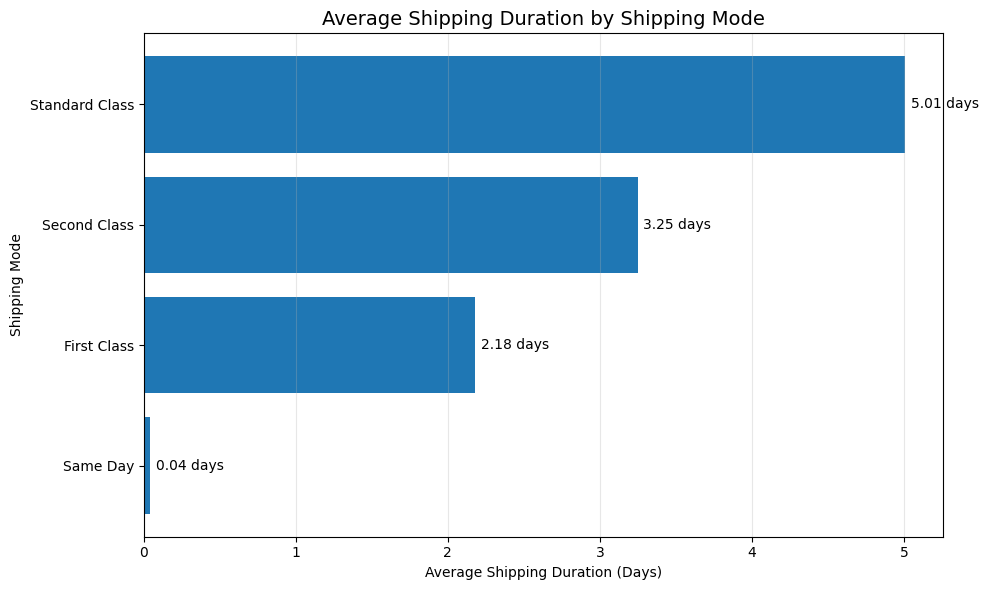

In [34]:
# Average Shipping Duration by Shipping Mode

shipping_duration_chart = shipping_duration.sort_values(
    "Average_Shipping_Days",
    ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    shipping_duration_chart["Ship Mode"],
    shipping_duration_chart["Average_Shipping_Days"]
)

plt.title("Average Shipping Duration by Shipping Mode", fontsize=14)
plt.xlabel("Average Shipping Duration (Days)")
plt.ylabel("Shipping Mode")

plt.bar_label(
    bars,
    labels=[
        f"{value:.2f} days"
        for value in shipping_duration_chart["Average_Shipping_Days"]
    ],
    padding=4
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
# Shipping Duration Analysis - Order Level

shipping_data = df.copy()

shipping_data["Order Date"] = pd.to_datetime(
    shipping_data["Order Date"]
)

shipping_data["Ship Date"] = pd.to_datetime(
    shipping_data["Ship Date"]
)

# Keep one record per order
order_shipping = (
    shipping_data.groupby("Order ID")
    .agg(
        Ship_Mode=("Ship Mode", "first"),
        Order_Date=("Order Date", "first"),
        Ship_Date=("Ship Date", "first")
    )
    .reset_index()
)

# Calculate shipping duration
order_shipping["Shipping_Days"] = (
    order_shipping["Ship_Date"]
    - order_shipping["Order_Date"]
).dt.days

# Compare shipping modes
shipping_duration_final = (
    order_shipping.groupby("Ship_Mode")
    .agg(
        Average_Days=("Shipping_Days", "mean"),
        Median_Days=("Shipping_Days", "median"),
        Min_Days=("Shipping_Days", "min"),
        Max_Days=("Shipping_Days", "max"),
        Total_Orders=("Order ID", "count")
    )
    .reset_index()
    .sort_values("Average_Days")
)

display(shipping_duration_final.round(2))

print("Total unique orders:", order_shipping["Order ID"].nunique())

,Ship_Mode,Average_Days,Median_Days,Min_Days,Max_Days,Total_Orders
1,Same Day,0.05,0.0,0,1,261
0,First Class,2.19,2.0,1,4,772
2,Second Class,3.24,3.0,1,5,944
3,Standard Class,5.00,5.0,3,7,2945


Total unique orders: 4922
